# 02 · Mosquitto y la red local

[Índice MQTT](00_indice_mqtt.ipynb) · [Anterior](01_modelo_pubsub_y_protocolo.ipynb) · [Siguiente](03_topics_y_contrato_de_datos.ipynb)

## Dónde se ejecuta cada pieza

Eclipse Mosquitto es el proceso que escucha MQTT. `mosquitto_pub` y `mosquitto_sub` son clientes de diagnóstico. El equipo del broker puede ejecutar también el backend; cada proceso tiene un puerto y un propósito.

| Proceso | Puerto habitual en el proyecto | Habla con |
| --- | --- | --- |
| Mosquitto | `1883/tcp` | ESP32, backend y herramientas MQTT |
| Backend HTTP | `8000/tcp` | Navegador o proxy de desarrollo |
| PostgreSQL | `5432/tcp` | Backend y herramientas de administración |

`127.0.0.1` siempre designa la máquina donde corre el cliente. Para el backend en el mismo equipo que Mosquitto, es una opción válida. Para la placa física, configura la IP LAN del equipo, por ejemplo `192.168.1.25`, en `MonitorAire/data/config.json`. Si el backend está en otro equipo, configura por separado `MQTT_HOST` y `MQTT_PORT` en `backend/.env` con la dirección alcanzable desde ese equipo. `0.0.0.0` en un listener significa escuchar en todas las interfaces IPv4 locales; los clientes se conectan a una dirección concreta.

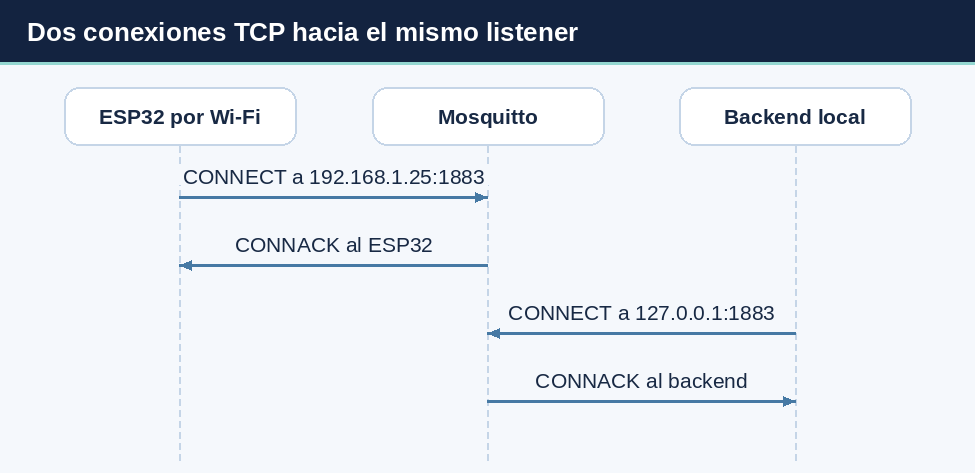

## Arranque en la LAN de la práctica

El archivo `backend/scripts/mosquitto.conf` declara estas dos opciones.

```conf
listener 1883 0.0.0.0
allow_anonymous true
```

Arranca el broker desde la raíz `ESP32` y mantén esta terminal abierta. Si ya hay un servicio Mosquitto atendiendo el mismo puerto, consúltalo antes de arrancar otro listener.

```bash
mosquitto -c backend/scripts/mosquitto.conf -v
```

En otra terminal del equipo comprueba que un proceso escucha y observa los temas de la placa.

```bash
ss -ltn 'sport = :1883'

mosquitto_sub -h 127.0.0.1 -p 1883 -V mqttv311 -q 1 -v \
  -t 'dispositivo/ESP32_S3_0001/#'
```

`-c` indica la configuración del broker, `-v` muestra actividad y `-q 1` pide el máximo QoS para esa suscripción. Desde otra máquina de la red propia, repite la suscripción con la IP LAN del equipo del broker. Si la prueba local conecta y la remota no, revisa la IP, la red Wi-Fi, el listener y el alcance del firewall; en redes educativas o de invitados el aislamiento entre clientes puede impedir el acceso directo. Los filtros MQTT se consultan después de verificar el enlace TCP. [Manual de Mosquitto](https://mosquitto.org/man/mosquitto-conf-5.html) · [Manual de mosquitto_sub](https://mosquitto.org/man/mosquitto_sub-1.html)

En el ESP32, ajusta los valores de Wi-Fi y MQTT en el archivo local `MonitorAire/data/config.json`. `MQTT_PORT` debe ser un número JSON.

```json
{
  "SSID": "MI_RED",
  "PASS": "MI_CLAVE_WIFI",
  "MQTT_HOST": "192.168.1.25",
  "MQTT_PORT": 1883
}
```

Para que el firmware use los cambios, carga el archivo de configuración al LittleFS de la placa durante la preparación del equipo. Una nueva carga de la imagen del sistema de archivos reemplaza el contenido existente, incluido el CSV pendiente. En el backend, `MQTT_HOST` también puede nombrar un host resoluble; el valor predeterminado es `127.0.0.1`. Configura un ID distinto para cada placa y evita ejecutar más de una instancia del consumidor integrado con el mismo Client ID.

## Laboratorio aislado en 18883

Practica estas publicaciones en tres terminales con un broker propio, fuera del servicio de la LAN. Los nombres bajo `laboratorio/` se usan solo para este ejercicio. La primera terminal crea la configuración temporal y queda atendiendo clientes hasta pulsar Ctrl+C.

```bash
mqtt_lab_dir="$(mktemp -d)"
cat > "$mqtt_lab_dir/mosquitto.conf" <<'CONF'
listener 18883 127.0.0.1
allow_anonymous true
persistence false
CONF
mosquitto -c "$mqtt_lab_dir/mosquitto.conf" -v
```

En la segunda terminal, inicia el observador y espera que aparezca SUBACK en las trazas del broker.

```bash
mosquitto_sub -h 127.0.0.1 -p 18883 -V mqttv311 -q 1 -v \
  -t 'laboratorio/+/medicion' -C 1 -W 15
```

En la tercera terminal, publica. `-C 1` hace salir al suscriptor tras un mensaje; `-W 15` limita la espera.

```bash
mosquitto_pub -h 127.0.0.1 -p 18883 -V mqttv311 -q 1 \
  -t 'laboratorio/mesa1/medicion' -m '25.6'
```

Salida esperada de la segunda terminal. La columna inicial es el tema, al que sigue el payload. El valor es una cadena al nivel de MQTT.

```text
laboratorio/mesa1/medicion 25.6
```

Ahora publica un valor retenido y suscríbete **después**. El broker entrega el valor al nuevo observador.

```bash
mosquitto_pub -h 127.0.0.1 -p 18883 -V mqttv311 -q 1 -r \
  -t 'laboratorio/mesa1/estado' -m 'conectado'
mosquitto_sub -h 127.0.0.1 -p 18883 -V mqttv311 -q 1 -v \
  -t 'laboratorio/mesa1/estado' -C 1 -W 5
```

Al terminar, detén este broker con Ctrl+C. La persistencia está desactivada en el laboratorio; las publicaciones retenidas de la prueba desaparecen al detenerlo. [Manual de mosquitto_pub](https://mosquitto.org/man/mosquitto_pub-1.html) · [Manual de mosquitto_sub](https://mosquitto.org/man/mosquitto_sub-1.html)

## Alcance de red y controles

El listener del proyecto permite clientes anónimos, usa TCP en claro y escucha en todas las interfaces IPv4. El archivo tampoco declara persistencia en disco. Esto permite observar la práctica en una LAN controlada; la protección del dashboard con cookie y JWT opera en HTTP y es independiente del puerto MQTT. En la configuración de la práctica, limita el alcance del puerto a la red prevista y evita exponerlo a Internet. Para un entorno compartido, la autenticación identifica al cliente, TLS protege el transporte y las ACL definen qué temas puede publicar o leer cada identidad. Esos controles requieren configurar el broker **y** sus clientes y verificar que la placa valida correctamente el servidor. La conservación de telemetría histórica corresponde a la cola de la placa y a PostgreSQL. [Configuración de Mosquitto](https://mosquitto.org/man/mosquitto-conf-5.html)

**Preguntas de revisión.** ¿Qué IP usa un backend que comparte equipo con Mosquitto? ¿Por qué un ESP32 conectado por Wi-Fi necesita la dirección LAN? ¿Qué capa investigarías cuando el cliente local funciona y el remoto no?

[Índice MQTT](00_indice_mqtt.ipynb) · [Anterior](01_modelo_pubsub_y_protocolo.ipynb) · [Siguiente](03_topics_y_contrato_de_datos.ipynb)